# LAB 05 - Sequence Models: RNN, LSTM, GRU

Bài toán: sentiment classification trên IMDb (positive / negative), giống LAB 04 nhưng thay representation tĩnh bằng sequence model.

Pipeline: raw text → tokenizer → vocabulary → token IDs → padding / truncation → embedding → RNN / LSTM / GRU → hidden state → linear → sentiment.

Load dữ liệu, làm sạch và split dùng lại `lab4/preprocessing.py`, nên split train/validation/test giống hệt LAB 04 và so sánh được với baseline. Cell RNN tự viết nằm trong `rnn_cell.py`. Notebook ghi `results.csv`, `learning_curves.png`, `confusion_matrix.png`, `sequence_length.png`, `gradient_by_position.png`.

## 0. Setup

In [1]:
import os
import sys
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, confusion_matrix,
                             f1_score, precision_score, recall_score)
from sklearn.pipeline import Pipeline

sys.path.insert(0, os.path.abspath("../lab4"))
from preprocessing import (LABEL_NAMES, class_distribution, clean_text, deduplicate, inspect_dataset,
                           load_imdb, preprocess, remove_overlap, split_train_val, tokenize)
from rnn_cell import SimpleRNNCell, lab_example_cell

SEED = 42
QUICK = os.environ.get("LAB5_QUICK") == "1"   # chạy thử nhanh trên tập con, không dùng cho kết quả nộp
torch.set_num_threads(8)
pd.set_option("display.max_colwidth", 200)

# Cấu hình chung cho mọi sequence model, chỉ thay recurrent layer
MAX_VOCAB = 20000        # 20,000 từ phổ biến nhất trong train, + PAD + UNK
EMBED_DIM = 100
HIDDEN = 128
DROPOUT = 0.3
BATCH = 64
LR = 1e-3
EPOCHS = 2 if QUICK else 8
CLIP = 1.0               # gradient clipping chống exploding gradient
MAX_LEN = 200            # độ dài mặc định, chọn ở mục 1
PAD, UNK = 0, 1

RESULTS = []
def log(experiment, model, setting, split, metric, value):
    RESULTS.append({"experiment": experiment, "model": model, "setting": setting,
                    "split": split, "metric": metric, "value": value})

def metrics(y_true, y_pred):
    # positive (label 1) là positive class
    return {"accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred, zero_division=0),
            "f1": f1_score(y_true, y_pred, zero_division=0)}

print("torch", torch.__version__, "| device: CPU, threads:", torch.get_num_threads(), "| QUICK =", QUICK)

torch 2.13.0+cpu | device: CPU, threads: 8 | QUICK = False


## 1. Experiment 1 - Dataset inspection

In [2]:
train_raw, test_raw = load_imdb()
inspection = pd.DataFrame([inspect_dataset(train_raw, "train"), inspect_dataset(test_raw, "test")]).set_index("split")
for split, row in inspection.iterrows():
    for k, v in row.items():
        log("exp1_inspection", "-", "raw", split, k, v)
inspection.round(1)

,samples,classes,missing_text,missing_label,duplicate_docs,len_mean,len_median,len_min,len_max
split,,,,,,,,,
train,25000,2,0,0,96,233.6,174.0,10,2473
test,25000,2,0,0,199,228.3,172.0,6,2246


In [3]:
overlap = set(train_raw["text"]) & set(test_raw["text"])
print("Document trùng giữa train và test:", len(overlap))
pd.concat({"train": class_distribution(train_raw), "test": class_distribution(test_raw)}, axis=1).round(2)

Document trùng giữa train và test: 123


train              test           
          Count Percentage  Count Percentage
Class                                       
negative  12500       50.0  12500       50.0
positive  12500       50.0  12500       50.0

Làm sạch và chia dữ liệu giống LAB 04: bỏ duplicate trong từng tập, bỏ review test đã có trong train, chia train thành train/validation 80/20 (stratified, seed 42). Vocabulary chỉ build trên train, validation dùng để chọn epoch, test chỉ dùng để báo cáo.

In [4]:
train_full = deduplicate(train_raw)
test_df = remove_overlap(deduplicate(test_raw), train_full)
train_df, val_df = split_train_val(train_full, val_size=0.2, seed=SEED)
if QUICK:
    train_df = train_df.sample(2000, random_state=SEED).reset_index(drop=True)
    val_df = val_df.sample(500, random_state=SEED).reset_index(drop=True)
    test_df = test_df.sample(1000, random_state=SEED).reset_index(drop=True)

X_train, y_train = train_df["text"].tolist(), train_df["label"].values
X_val, y_val = val_df["text"].tolist(), val_df["label"].values
X_test, y_test = test_df["text"].tolist(), test_df["label"].values

tok_train = [preprocess(t) for t in X_train]
tok_val = [preprocess(t) for t in X_val]
tok_test = [preprocess(t) for t in X_test]

split_stats = pd.DataFrame({name: {"samples": len(d), "positive %": 100 * d["label"].mean()}
                            for name, d in [("train", train_df), ("validation", val_df), ("test", test_df)]}).T
for split, row in split_stats.iterrows():
    log("exp1_split", "-", "dedup", split, "samples", row["samples"])
    log("exp1_split", "-", "dedup", split, "positive_pct", row["positive %"])
split_stats.round(2)

,samples,positive %
train,19923.0,50.08
validation,4981.0,50.09
test,24678.0,50.30


### Sequence length

Độ dài tính bằng số token sau tokenizer (giống LAB 02 - 04). Với mỗi max_length L: tỉ lệ review không bị cắt (độ dài ≤ L) và tỉ lệ token được giữ lại = Σ min(len, L) / Σ len.

In [5]:
len_train = np.array([len(t) for t in tok_train])
len_stats = pd.Series({"min": len_train.min(), "p25": np.percentile(len_train, 25), "median": np.median(len_train),
                       "mean": len_train.mean(), "p75": np.percentile(len_train, 75), "p90": np.percentile(len_train, 90),
                       "p95": np.percentile(len_train, 95), "max": len_train.max()})
for k, v in len_stats.items():
    log("exp1_length", "-", "train", "train", f"len_{k}", v)
print(len_stats.round(1).to_dict())

def retained(lengths, L):
    return {"reviews_not_truncated_%": 100 * (lengths <= L).mean(),
            "tokens_retained_%": 100 * np.minimum(lengths, L).sum() / lengths.sum()}

cover = pd.DataFrame({L: retained(len_train, L) for L in [30, 50, 100, 200, 300, 400, 500]}).T.rename_axis("max_length")
for L, row in cover.iterrows():
    for k, v in row.items():
        log("exp1_length", "-", f"L={L}", "train", k, v)
cover.round(1)

{'min': 10.0, 'p25': 127.0, 'median': 174.0, 'mean': 233.4, 'p75': 284.0, 'p90': 457.0, 'p95': 596.9, 'max': 2473.0}


,reviews_not_truncated_%,tokens_retained_%
max_length,,
30,0.2,12.8
50,2.4,21.3
100,12.2,41.2
200,58.5,68.2
300,77.1,81.5
400,86.6,89.0
500,92.0,93.5


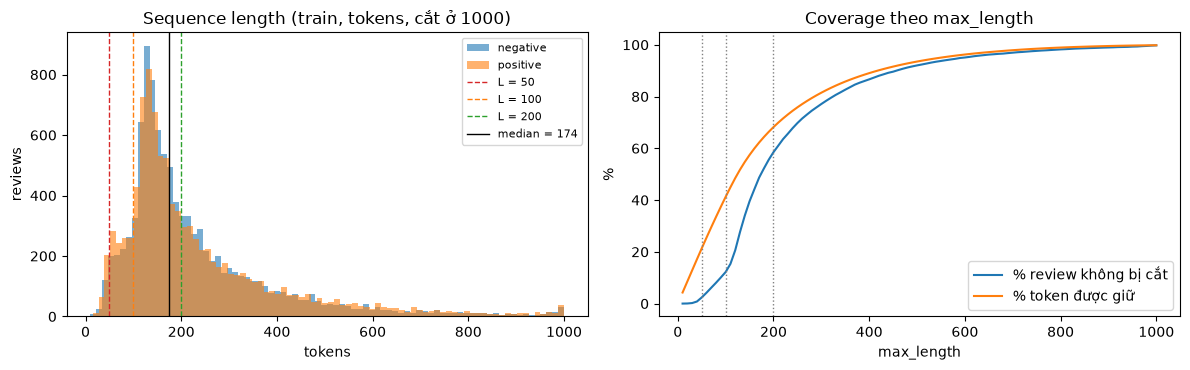

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for lab, name in LABEL_NAMES.items():
    axes[0].hist(len_train[y_train == lab].clip(max=1000), bins=80, alpha=0.6, label=name)
for L, c in [(50, "tab:red"), (100, "tab:orange"), (200, "tab:green")]:
    axes[0].axvline(L, color=c, ls="--", lw=1, label=f"L = {L}")
axes[0].axvline(np.median(len_train), color="k", lw=1, label=f"median = {np.median(len_train):.0f}")
axes[0].set(title="Sequence length (train, tokens, cắt ở 1000)", xlabel="tokens", ylabel="reviews")
axes[0].legend(fontsize=8)
Ls = np.arange(10, 1001, 10)
axes[1].plot(Ls, [retained(len_train, L)["reviews_not_truncated_%"] for L in Ls], label="% review không bị cắt")
axes[1].plot(Ls, [retained(len_train, L)["tokens_retained_%"] for L in Ls], label="% token được giữ")
for L in [50, 100, 200]:
    axes[1].axvline(L, color="gray", ls=":", lw=1)
axes[1].set(title="Coverage theo max_length", xlabel="max_length", ylabel="%")
axes[1].legend()
plt.tight_layout()
plt.savefig("sequence_length_hist.png", dpi=120)
plt.show()

**Chọn max_length dựa trên thông tin nào?** Dựa trên phân phối độ dài và lượng thông tin bị mất, không dựa trên tốc độ chạy:

- Median 174 token, mean 233, p90 457, max 2,473. Phân phối lệch phải, đuôi dài.
- L = 200 (gần median): 58.5% review không bị cắt, giữ 68.2% token. L = 50 chỉ giữ 21.3% token, gần như mọi review bị cắt (chỉ 2.4% nguyên vẹn). Muốn giữ khoảng 90% token cần L khoảng 400 - 500.
- Chi phí của RNN tăng tuyến tính theo L (đo ở mục 7), và gradient tới các token xa yếu dần, nên tăng L tới p95 không chắc có lợi.
- Ngoài độ dài còn phải xét **thông tin nằm ở đâu**: review IMDb thường kết luận ở cuối ("8/10", "highly recommended"), nên truncate head làm mất đúng phần đó (kiểm tra ở mục 7 bằng truncation tail).

Chọn L = 200 làm mặc định: phủ hơn nửa số review trọn vẹn và khoảng 2/3 lượng token, với chi phí train vừa phải trên CPU.

## 2. Tokenization, vocabulary, padding và truncation

- Vocabulary: 20,000 từ phổ biến nhất trong **train**, id 0 = PAD, id 1 = UNK. Từ ngoài vocabulary → UNK.
- Padding: thêm PAD vào **cuối** cho đủ L. PAD không phải thông tin ngôn ngữ: embedding của PAD là vector 0 (`padding_idx`), và model đọc hidden state tại token thật cuối cùng, nên PAD không ảnh hưởng tới prediction.
- Truncation: review dài hơn L bị cắt. Mặc định giữ L token **đầu** (head), mục 7 thử thêm giữ L token cuối (tail).

In [7]:
counter = Counter(w for toks in tok_train for w in toks)
itos = ["<pad>", "<unk>"] + [w for w, _ in counter.most_common(MAX_VOCAB)]
stoi = {w: i for i, w in enumerate(itos)}
VOCAB_SIZE = len(itos)

def encode(tokens):
    return [stoi.get(w, UNK) for w in tokens]

def pad_truncate(ids, L, mode="head"):
    """Trả về (ids độ dài đúng L, độ dài thật sau khi cắt). mode: head giữ L token đầu, tail giữ L token cuối."""
    ids = ids[:L] if mode == "head" else ids[-L:]
    n = max(len(ids), 1)                  # review rỗng: giữ 1 PAD để có hidden state
    return ids + [PAD] * (L - len(ids)), n

ids_train, ids_val, ids_test = ([encode(t) for t in toks] for toks in (tok_train, tok_val, tok_test))

def unk_rate(ids_list):
    flat = np.concatenate([np.array(x) for x in ids_list if x])
    return 100 * (flat == UNK).mean()

print("Số từ khác nhau trong train:", len(counter), "| vocabulary dùng cho model:", VOCAB_SIZE)
print("Tỉ lệ token là UNK - train: %.2f%%, validation: %.2f%%, test: %.2f%%"
      % (unk_rate(ids_train), unk_rate(ids_val), unk_rate(ids_test)))
log("vocab", "-", "-", "train", "distinct_words", len(counter))
log("vocab", "-", "-", "-", "vocab_size", VOCAB_SIZE)
for split, ids in [("train", ids_train), ("validation", ids_val), ("test", ids_test)]:
    log("vocab", "-", "-", split, "unk_rate_pct", unk_rate(ids))

example = "I really like this movie"
ex_ids = encode(preprocess(example))
print(f"\n{example!r} → tokens {preprocess(example)} → ids {ex_ids}")
print("Padding L = 8:   ", pad_truncate(ex_ids, 8)[0])
print("Truncation L = 3 (head):", pad_truncate(ex_ids, 3)[0], "| (tail):", pad_truncate(ex_ids, 3, "tail")[0])

Số từ khác nhau trong train: 73763 | vocabulary dùng cho model: 20002


Tỉ lệ token là UNK - train: 2.58%, validation: 2.95%, test: 3.33%



'I really like this movie' → tokens ['i', 'really', 'like', 'this', 'movie'] → ids [10, 63, 37, 11, 17]
Padding L = 8:    [10, 63, 37, 11, 17, 0, 0, 0]
Truncation L = 3 (head): [10, 63, 37] | (tail): [37, 11, 17]


In [8]:
def to_tensors(ids_list, L, mode="head"):
    pairs = [pad_truncate(x, L, mode) for x in ids_list]
    return torch.tensor([p[0] for p in pairs]), torch.tensor([p[1] for p in pairs])

## 3. Core implementation - Simple RNN cell

`rnn_cell.py` implement h_t = tanh(W_xh x_t + W_hh h_(t-1) + b_h) bằng NumPy. Kiểm tra với Bài 1 và với `torch.nn.RNNCell` / `torch.nn.RNN` khi dùng chung weight.

```
   x_t
    │
    ▼
  W_xh x_t ──┐
             ▼
             + ◄── W_hh h_(t-1)  ◄── h_(t-1) (từ bước trước)
             │ + b_h
             ▼
           tanh
             │
             ▼
            h_t ──► bước t+1 (thành h_(t-1) mới) / classifier nếu t = T
```

In [9]:
cell = lab_example_cell()
h_t, a_t = cell.forward([1, 0], [0.5, 0.2])
print("Bài 1: W_xh x_t =", cell.W_xh @ np.array([1, 0]), " W_hh h_(t-1) =", cell.W_hh @ np.array([0.5, 0.2]))
print("       a_t =", a_t.round(4), " h_t = tanh(a_t) =", h_t.round(5))
t_cell = cell.to_torch()
print("torch.nn.RNNCell:", t_cell(torch.tensor([[1.0, 0.0]], dtype=torch.float64),
                                torch.tensor([[0.5, 0.2]], dtype=torch.float64)).detach().numpy().round(5))

# So với torch.nn.RNN trên một sequence ngẫu nhiên (T = 6, batch = 3)
torch.manual_seed(SEED)
t_rnn = nn.RNN(5, 4).double()
mine = SimpleRNNCell(5, 4)
mine.W_xh, mine.W_hh = t_rnn.weight_ih_l0.detach().numpy().copy(), t_rnn.weight_hh_l0.detach().numpy().copy()
mine.b_h = (t_rnn.bias_ih_l0 + t_rnn.bias_hh_l0).detach().numpy().copy()
xs = torch.randn(6, 3, 5, dtype=torch.float64)
out_t, _ = t_rnn(xs)
print("max |h_mine - h_torch| trên cả sequence:", np.abs(mine.forward_sequence(xs.numpy()) - out_t.detach().numpy()).max())

Bài 1: W_xh x_t = [0.5 0.1]  W_hh h_(t-1) = [0.17 0.2 ]
       a_t = [0.67 0.3 ]  h_t = tanh(a_t) = [0.58498 0.29131]
torch.nn.RNNCell: [[0.58498 0.29131]]
max |h_mine - h_torch| trên cả sequence: 1.1102230246251565e-16


Thứ tự từ: với cùng embedding, "dog bites man" và "man bites dog" có cùng vector trung bình nhưng h_T khác nhau.

In [10]:
rng = np.random.default_rng(SEED)
toy_emb = {w: rng.normal(size=5) for w in ["dog", "bites", "man"]}
for s in ["dog bites man", "man bites dog"]:
    seq = np.stack([toy_emb[w] for w in s.split()])
    print(f"{s:15s} mean = {seq.mean(0).round(3)}  h_T = {mine.forward_sequence(seq)[-1].round(3)}")

dog bites man   mean = [-0.039 -0.045  0.167  0.684 -0.779]  h_T = [0.932 0.577 0.416 0.362]
man bites dog   mean = [-0.039 -0.045  0.167  0.684 -0.779]  h_T = [ 0.696  0.966 -0.176 -0.42 ]


## 4. Sequence classifier và training loop

Model: Embedding(V, 100, padding_idx = 0) → RNN / LSTM / GRU (1 layer, hidden 128, một chiều) → dropout 0.3 → Linear(128, 1) → sigmoid.

- Hidden state dùng cho classifier là h tại **token thật cuối cùng** (vị trí length - 1). Vì PAD nằm sau và RNN đọc trái sang phải, các h_t với t < length không bị PAD ảnh hưởng. Kết quả giống `pack_padded_sequence`, kiểm tra ở cell dưới, nhưng nhanh hơn khoảng 3 lần trên CPU.
- Loss: binary cross-entropy. Optimizer Adam, lr = 1e-3, batch 64, gradient clipping norm 1.0.
- Train 8 epoch, sau mỗi epoch tính validation loss, giữ lại weight của epoch có **validation loss thấp nhất** (early stopping kiểu checkpoint). Test chỉ đánh giá một lần với weight đó.
- Mọi model dùng chung vocabulary, embedding dim, hidden size, batch size, optimizer, lr, số epoch, seed và split. Chỉ thay recurrent layer.

In [11]:
RNN_TYPES = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}

class SeqClassifier(nn.Module):
    def __init__(self, rnn_type, vocab_size=None, embed_dim=EMBED_DIM, hidden=HIDDEN, dropout=DROPOUT):
        super().__init__()
        self.rnn_type = rnn_type
        self.emb = nn.Embedding(vocab_size or VOCAB_SIZE, embed_dim, padding_idx=PAD)
        self.rnn = RNN_TYPES[rnn_type](embed_dim, hidden, batch_first=True)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden, 1)

    def last_hidden(self, e, lengths):
        out, _ = self.rnn(e)                                   # (B, L, H): h_1 ... h_L
        return out[torch.arange(len(lengths)), lengths - 1]    # h tại token thật cuối cùng

    def forward_embedded(self, e, lengths):
        return self.fc(self.drop(self.last_hidden(e, lengths))).squeeze(1)   # logit z

    def forward(self, ids, lengths):
        return self.forward_embedded(self.emb(ids), lengths)

def n_params(model):
    return sum(p.numel() for p in model.parameters())

def n_params_recurrent(model):
    return sum(p.numel() for p in model.rnn.parameters())

# Kiểm tra: lấy h tại length - 1 == h_n của pack_padded_sequence
torch.manual_seed(SEED)
for t in RNN_TYPES:
    m = SeqClassifier(t).eval()
    ids, lens = to_tensors(ids_val[:16], 50)
    e = m.emb(ids)
    packed = nn.utils.rnn.pack_padded_sequence(e, lens, batch_first=True, enforce_sorted=False)
    _, h_n = m.rnn(packed)
    h_n = (h_n[0] if isinstance(h_n, tuple) else h_n)[-1]
    print(f"{t:4s} max |gather - packed| = {(m.last_hidden(e, lens) - h_n).abs().max().item():.2e} | "
          f"params: total {n_params(m):,}, recurrent {n_params_recurrent(m):,}")

RNN  max |gather - packed| = 0.00e+00 | params: total 2,029,769, recurrent 29,440
LSTM max |gather - packed| = 8.94e-08 | params: total 2,118,089, recurrent 117,760
GRU  max |gather - packed| = 0.00e+00 | params: total 2,088,649, recurrent 88,320


In [12]:
@torch.no_grad()
def predict_proba(model, ids, lens, batch=512):
    model.eval()
    return torch.cat([torch.sigmoid(model(ids[i:i + batch], lens[i:i + batch]))
                      for i in range(0, len(ids), batch)]).numpy()

def bce(p, y):
    p = np.clip(p, 1e-7, 1 - 1e-7)
    return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))

def train_model(rnn_type, L=MAX_LEN, mode="head", epochs=EPOCHS, seed=SEED, verbose=True):
    torch.manual_seed(seed)
    np.random.seed(seed)
    Xtr, Ltr = to_tensors(ids_train, L, mode)
    Xva, Lva = to_tensors(ids_val, L, mode)
    ytr = torch.tensor(y_train, dtype=torch.float32)
    model = SeqClassifier(rnn_type)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    gen = torch.Generator().manual_seed(seed)
    history, best = [], None
    t_start = time.perf_counter()
    for ep in range(1, epochs + 1):
        model.train()
        t0 = time.perf_counter()
        perm = torch.randperm(len(Xtr), generator=gen)
        tot, n, grad_norms = 0.0, 0, []
        for i in range(0, len(perm), BATCH):
            idx = perm[i:i + BATCH]
            loss = F.binary_cross_entropy_with_logits(model(Xtr[idx], Ltr[idx]), ytr[idx])
            opt.zero_grad()
            loss.backward()
            grad_norms.append(nn.utils.clip_grad_norm_(model.parameters(), CLIP).item())
            opt.step()
            tot += loss.item() * len(idx); n += len(idx)
        epoch_time = time.perf_counter() - t0
        p_val = predict_proba(model, Xva, Lva)
        m_val = metrics(y_val, (p_val >= 0.5).astype(int))
        history.append({"epoch": ep, "train_loss": tot / n, "val_loss": bce(p_val, y_val),
                        "val_accuracy": m_val["accuracy"], "val_f1": m_val["f1"], "epoch_time_s": epoch_time,
                        "grad_norm_median": float(np.median(grad_norms)),
                        "clipped_%": 100 * float(np.mean(np.array(grad_norms) > CLIP))})
        if best is None or history[-1]["val_loss"] < best[0]:
            best = (history[-1]["val_loss"], ep, {k: v.clone() for k, v in model.state_dict().items()})
        if verbose:
            h = history[-1]
            print(f"  [{rnn_type} L={L} {mode}] epoch {ep}: train_loss {h['train_loss']:.4f} val_loss {h['val_loss']:.4f} "
                  f"val_acc {h['val_accuracy']:.4f} ({epoch_time:.0f} s, grad norm median {h['grad_norm_median']:.2f})")
    total_time = time.perf_counter() - t_start
    model.load_state_dict(best[2])
    model.eval()
    info = {"model": rnn_type, "max_length": L, "truncation": mode, "best_epoch": best[1],
            "train_time_s": total_time, "time_per_epoch_s": np.mean([h["epoch_time_s"] for h in history]),
            "params_total": n_params(model), "params_recurrent": n_params_recurrent(model)}
    return model, pd.DataFrame(history), info

def activation_memory_mb(rnn_type, L, batch=BATCH):
    """Bộ nhớ các tensor được lưu lại cho backward (activation) trong một forward của 1 batch, không tính weight."""
    torch.manual_seed(SEED)
    model = SeqClassifier(rnn_type).train()
    param_ptrs = {p.data_ptr() for p in model.parameters()}
    seen, total = set(), [0]
    def pack(t):
        key = (t.data_ptr(), t.numel())
        if t.data_ptr() not in param_ptrs and key not in seen:
            seen.add(key); total[0] += t.numel() * t.element_size()
        return t
    ids, lens = to_tensors(ids_train[:batch], L)
    with torch.autograd.graph.saved_tensors_hooks(pack, lambda t: t):
        model(ids, lens).sum()
    return total[0] / 2**20

def evaluate(model, L=MAX_LEN, mode="head"):
    Xte, Lte = to_tensors(ids_test, L, mode)
    p = predict_proba(model, Xte, Lte)
    return p, metrics(y_test, (p >= 0.5).astype(int))

def log_run(experiment, info, history, m_test, setting):
    name = info["model"]
    for k in ["max_length", "best_epoch", "train_time_s", "time_per_epoch_s", "params_total", "params_recurrent"]:
        log(experiment, name, setting, "-", k, info[k])
    for _, h in history.iterrows():
        for k in ["train_loss", "val_loss", "val_accuracy", "val_f1", "epoch_time_s"]:
            log(experiment, name, f"{setting} epoch={int(h['epoch'])}", "train" if k == "train_loss" else "validation", k, h[k])
    for k, v in m_test.items():
        log(experiment, name, setting, "test", k, v)

## 5. Experiment 3 - Baseline TF-IDF + Logistic Regression (LAB 04)

Giống LAB 04: TF-IDF unigram (min_df = 2, sublinear tf) + Logistic Regression, chọn C theo F1 trên validation. TF-IDF dùng toàn bộ review, không cắt.

In [13]:
def tfidf(**kw):
    params = dict(preprocessor=clean_text, tokenizer=tokenize, token_pattern=None,
                  lowercase=False, min_df=2, sublinear_tf=True)
    params.update(kw)
    return TfidfVectorizer(**params)

best = None
for C in [0.25, 1, 4, 16]:
    pipe = Pipeline([("tfidf", tfidf()), ("clf", LogisticRegression(C=C, max_iter=2000))])
    t0 = time.perf_counter(); pipe.fit(X_train, y_train); fit_time = time.perf_counter() - t0
    f1_val = f1_score(y_val, pipe.predict(X_val))
    if best is None or f1_val > best[1]:
        best = (C, f1_val, pipe, fit_time)
C_best, _, baseline, base_time = best
p_base = baseline.predict_proba(X_test)[:, 1]
m_base = metrics(y_test, (p_base >= 0.5).astype(int))
base_vocab = len(baseline.named_steps["tfidf"].vocabulary_)
base_params = base_vocab + 1
for k, v in {**m_base, "train_time_s": base_time, "C": C_best, "vocab_size": base_vocab, "params_total": base_params}.items():
    log("exp3_baseline", "TF-IDF + LR", "unigram", "test" if k in m_base else "-", k, v)
print(f"C = {C_best}, vocabulary = {base_vocab:,}, train time = {base_time:.1f} s")
pd.Series(m_base).round(4)

C = 4, vocabulary = 43,172, train time = 3.6 s


accuracy     0.8899
precision    0.8915
recall       0.8894
f1           0.8904
dtype: float64

## 6. Experiment 4 - RNN vs LSTM vs GRU (max_length = 200)

In [14]:
models, histories, infos, test_proba, test_metrics = {}, {}, {}, {}, {}
for t in ["RNN", "LSTM", "GRU"]:
    print(t)
    model, hist, info = train_model(t, MAX_LEN)
    p, m = evaluate(model, MAX_LEN)
    models[t], histories[t], infos[t], test_proba[t], test_metrics[t] = model, hist, info, p, m
    log_run("exp4_architecture", info, hist, m, f"L={MAX_LEN}")

arch = pd.DataFrame([{**{k: infos[t][k] for k in ["model", "params_total", "params_recurrent", "train_time_s",
                                                   "time_per_epoch_s", "best_epoch"]},
                      "val_loss_best": histories[t]["val_loss"].min(), **test_metrics[t]} for t in models])
arch = pd.concat([pd.DataFrame([{"model": "TF-IDF + LR (baseline)", "params_total": base_params, "params_recurrent": 0,
                                 "train_time_s": base_time, **m_base}]), arch]).set_index("model")
arch.round(4)

RNN


  [RNN L=200 head] epoch 1: train_loss 0.6880 val_loss 0.7044 val_acc 0.4899 (38 s, grad norm median 0.61)


  [RNN L=200 head] epoch 2: train_loss 0.6391 val_loss 0.6121 val_acc 0.6766 (31 s, grad norm median 0.68)


  [RNN L=200 head] epoch 3: train_loss 0.5726 val_loss 0.5898 val_acc 0.7063 (29 s, grad norm median 0.86)


  [RNN L=200 head] epoch 4: train_loss 0.5211 val_loss 0.5423 val_acc 0.7480 (31 s, grad norm median 0.95)


...

  [GRU L=200 head] epoch 5: train_loss 0.1765 val_loss 0.4091 val_acc 0.8639 (87 s, grad norm median 0.86)


  [GRU L=200 head] epoch 6: train_loss 0.1196 val_loss 0.4022 val_acc 0.8579 (102 s, grad norm median 0.83)


  [GRU L=200 head] epoch 7: train_loss 0.0704 val_loss 0.5099 val_acc 0.8637 (97 s, grad norm median 0.67)


  [GRU L=200 head] epoch 8: train_loss 0.0432 val_loss 0.5535 val_acc 0.8621 (68 s, grad norm median 0.55)


,params_total,params_recurrent,train_time_s,accuracy,precision,recall,f1,time_per_epoch_s,best_epoch,val_loss_best
model,,,,,,,,,,
TF-IDF + LR (baseline),43173,0,3.6436,0.8899,0.8915,0.8894,0.8904,NaN,NaN,NaN
RNN,2029769,29440,243.2427,0.7499,0.7524,0.7494,0.7509,29.5921,5.0,0.5420
LSTM,2118089,117760,293.7533,0.8246,0.8194,0.8354,0.8273,34.9413,5.0,0.4162
GRU,2088649,88320,776.0531,0.8493,0.8310,0.8790,0.8543,93.9943,4.0,0.3447


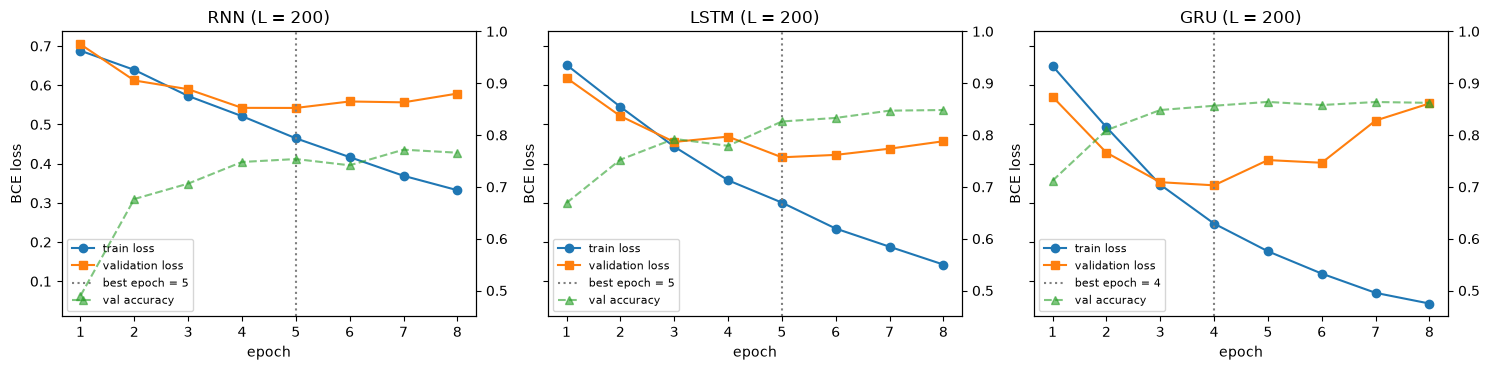

RNN                                                        LSTM  \
      train_loss val_loss val_accuracy grad_norm_median clipped_% train_loss   
epoch                                                                          
1         0.6880   0.7044       0.4899           0.6117   10.5769     0.6520   
2         0.6391   0.6121       0.6766           0.6771   20.5128     0.5449   
3         0.5726   0.5898       0.7063           0.8563   35.5769     0.4434   
4         0.5211   0.5423       0.7480           0.9545   45.1923     0.3576   
5         0.4646   0.5420       0.7537           1.0830   57.6923     0.3007   
6         0.4166   0.5585       0.7416           1.0684   55.1282     0.2345   
7         0.3690   0.5563       0.7717           1.1131   58.3333     0.1881   
8         0.3323   0.5787       0.7659           1.1812   62.8205     0.1426   

                                                              GRU           \
      val_loss val_accuracy grad_norm_median clipped_% train_loss val_loss   
epoch                                                                        
1       0.6185       0.6689           0.3808   12.8205     0.6490   0.5706   
2       0.5213       0.7525           0.6904   32.0513     0.4930   0.4281   
3       0.4554       0.7926           0.9412   45.1923     0.3464   0.3527   
4       0.4689       0.7792           1.0662   53.8462     0.2471   0.3447   
5       0.4162       0.8261           1.0193   51.2821     0.1765   0.4091   
6       0.4223       0.8330           0.9223   43.9103     0.1196   0.4022   
7       0.4381       0.8470           0.8648   38.7821     0.0704   0.5099   
8       0.4571       0.8482           0.7967   32.3718     0.0432   0.5535   

                                               
      val_accuracy grad_norm_median clipped_%  
epoch                                          
1           0.7119           0.4864   18.9103  
2           0.8093           0.8558   37.8205  
3           0.8482           0.9223   43.5897  
4           0.8565           0.9106   40.3846  
5           0.8639           0.8564   33.3333  
6           0.8579           0.8264   37.8205  
7           0.8637           0.6658   25.0000  
8           0.8621           0.5506   22.4359

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, (t, h) in zip(axes, histories.items()):
    ax.plot(h["epoch"], h["train_loss"], "o-", label="train loss")
    ax.plot(h["epoch"], h["val_loss"], "s-", label="validation loss")
    ax.axvline(infos[t]["best_epoch"], color="gray", ls=":", label=f"best epoch = {infos[t]['best_epoch']}")
    ax2 = ax.twinx()
    ax2.plot(h["epoch"], h["val_accuracy"], "^--", color="tab:green", alpha=0.6, label="val accuracy")
    ax2.set_ylim(0.45, 1.0)
    ax.set(title=f"{t} (L = {MAX_LEN})", xlabel="epoch", ylabel="BCE loss")
    lines = ax.get_legend_handles_labels(); l2 = ax2.get_legend_handles_labels()
    ax.legend(lines[0] + l2[0], lines[1] + l2[1], fontsize=8, loc="lower left")
plt.tight_layout()
plt.savefig("learning_curves.png", dpi=120)
plt.show()
pd.concat({t: h.set_index("epoch")[["train_loss", "val_loss", "val_accuracy", "grad_norm_median", "clipped_%"]]
           for t, h in histories.items()}, axis=1).round(4)

**Kết quả so với prediction:**

- LSTM (F1 0.827) và GRU (0.854) tốt hơn Simple RNN (0.751) rõ rệt, đúng Prediction 2. Cùng embedding, cùng dữ liệu, chỉ khác recurrent layer, nên chênh lệch đến từ cơ chế gate.
- **Không model sequence nào vượt TF-IDF + LR** (F1 0.890), sai với kỳ vọng 50% ở Prediction 1. Lý do chính ở mục 7 và 10: truncation ở 200 token làm mất 31% token và phần kết luận của review dài, và các model này không có pretrained embedding mà học embedding từ đầu trên 20K review.
- Accuracy và F1 không kể hết: GRU có recall 0.879 nhưng precision 0.831, tức nghiêng về đoán positive (FP 2,218 so với FN 1,502). TF-IDF cân bằng hơn (FP 1,344, FN 1,373).
- Chi phí: TF-IDF + LR có 43K tham số, train 3.6 s. Model sequence có khoảng 2.1 triệu tham số, phần lớn là embedding (20,002 × 100 = 2.0 triệu), recurrent layer chỉ 29K (RNN) / 118K (LSTM) / 88K (GRU). Train mất 4 - 13 phút. GRU ít tham số hơn LSTM nhưng chậm hơn khoảng 2.7 lần trên CPU này, vì PyTorch CPU có kernel tối ưu (oneDNN) cho LSTM. Số tham số không quyết định tốc độ.

**Learning curves - có overfitting không?** Có, ở cả ba model:

- Train loss giảm đều suốt 8 epoch (GRU 0.65 → 0.04, LSTM 0.65 → 0.14, RNN 0.69 → 0.33).
- Validation loss giảm tới epoch 4 - 5 rồi tăng lại: GRU 0.345 (epoch 4) → 0.554 (epoch 8), LSTM 0.416 → 0.457, RNN 0.542 → 0.579. Đây đúng là mẫu "train ↓↓↓, validation ↓↓ → ↑↑". GRU overfit mạnh nhất và sớm nhất.
- Validation accuracy của LSTM vẫn nhích lên (0.826 ở epoch 5 → 0.848 ở epoch 8) trong khi validation loss tăng: model ngày càng tự tin quá mức vào các mẫu sai, nên loss phạt nặng hơn dù số mẫu sai không tăng. Chọn checkpoint theo validation loss vì vậy có thể bỏ lỡ một chút accuracy (với LSTM), nhưng không được nhìn test để chọn lại.
- Gradient: trung vị gradient norm của RNN tăng từ 0.61 lên 1.18, và tới epoch 8 có 63% batch bị clip (norm > 1). Clipping giữ cho training ổn định.

### RNN có thực sự dùng thông tin thứ tự mà TF-IDF không dùng?

Bằng chứng trực tiếp: các cặp câu có **cùng bag-of-words**, chỉ khác thứ tự. TF-IDF cho hai câu cùng một vector (cos = 1) nên bắt buộc cùng P(pos). Nếu sequence model cho P(pos) khác nhau thì nó đang dùng thứ tự.

In [16]:
def proba_texts(model, texts, L=MAX_LEN, mode="head"):
    ids, lens = to_tensors([encode(preprocess(t)) for t in texts], L, mode)
    return predict_proba(model, ids, lens)

order_pairs = [
    ("this movie is good", "this movie is not good"),
    ("the movie was not bad , it was good", "the movie was not good , it was bad"),
    ("i expected it to be bad but it was great", "i expected it to be great but it was bad"),
    ("great actors , boring story", "boring actors , great story"),
    ("i loved it at first but now i hate it", "i hated it at first but now i love it"),
    ("good is movie this", "this movie is good"),
]
vec_base = baseline.named_steps["tfidf"]
rows = []
for s1, s2 in order_pairs:
    t1, t2 = vec_base.transform([s1, s2])
    r = {"S1": s1, "S2": s2, "cos TF-IDF": round(float((t1 @ t2.T).toarray()[0, 0]), 3),
         "TF-IDF+LR": tuple(baseline.predict_proba([s1, s2])[:, 1].round(3))}
    for t, m in models.items():
        r[t] = tuple(proba_texts(m, [s1, s2]).round(3))
    rows.append(r)
    for t in ["TF-IDF+LR"] + list(models):
        log("exp3_order", t, f"{s1} | {s2}", "-", "p_pos_S1", r[t][0])
        log("exp3_order", t, f"{s1} | {s2}", "-", "p_pos_S2", r[t][1])
pd.DataFrame(rows)

,S1,S2,cos TF-IDF,TF-IDF+LR,RNN,LSTM,GRU
0,this movie is good,this movie is not good,0.887,"(0.825, 0.37)","(0.393, 0.534)","(0.679, 0.462)","(0.845, 0.561)"
1,"the movie was not bad , it was good","the movie was not good , it was bad",1.000,"(0.002, 0.002)","(0.186, 0.119)","(0.258, 0.134)","(0.265, 0.095)"
2,i expected it to be bad but it was great,i expected it to be great but it was bad,1.000,"(0.37, 0.37)","(0.407, 0.33)","(0.694, 0.328)","(0.362, 0.285)"
3,"great actors , boring story","boring actors , great story",1.000,"(0.139, 0.139)","(0.465, 0.354)","(0.21, 0.405)","(0.209, 0.133)"
4,i loved it at first but now i hate it,i hated it at first but now i love it,0.420,"(0.993, 0.934)","(0.865, 0.547)","(0.923, 0.873)","(0.954, 0.93)"
5,good is movie this,this movie is good,1.000,"(0.825, 0.825)","(0.739, 0.393)","(0.453, 0.679)","(0.706, 0.845)"


**RNN có dùng thông tin thứ tự không? Có, và đây là bằng chứng trực tiếp:**

- Ở 4 cặp có cùng bag-of-words (cos TF-IDF = 1.000), TF-IDF + LR **bắt buộc** cho hai câu cùng P(pos), ví dụ "not bad, it was good" / "not good, it was bad" đều 0.002. Cả ba sequence model đều cho P(pos) khác nhau, nên output phụ thuộc vào thứ tự.
- Hướng thay đổi thường hợp lý: "not bad, ... good" > "not good, ... bad" ở cả ba model (LSTM 0.258 so với 0.134); "expected bad but it was great" > "expected great but it was bad" (LSTM 0.694 so với 0.328). "this movie is not good" giảm so với "this movie is good" ở LSTM (0.679 → 0.462) và GRU (0.845 → 0.561).
- Nhưng **không ổn định**: Simple RNN lại tăng P(pos) khi thêm "not" (0.393 → 0.534). "i loved it at first but now i hate it" bị cả bốn model đoán positive (LSTM 0.923), tức chưa model nào học được "but now" đảo nghĩa. Chuỗi vô nghĩa "good is movie this" cũng nhận P(pos) khác "this movie is good", nghĩa là thứ tự ảnh hưởng tới output nhưng không có nghĩa model hiểu ngữ pháp.

Kết luận: sequence model **có sử dụng** thứ tự (TF-IDF không thể), nhưng sử dụng được hay không còn tuỳ dữ liệu train. Lợi thế này không đủ bù cho việc mất thông tin do truncation, nên accuracy tổng thể vẫn thấp hơn TF-IDF.

## 7. Experiment 2 + 5 - Padding / truncation và sequence length

Giữ architecture cố định, chỉ đổi max_length ∈ {50, 100, 200} (truncation head). Làm với LSTM (model chính) và Simple RNN (để xem vanishing gradient ảnh hưởng thế nào khi sequence dài). Kết quả L = 200 dùng lại từ mục 6 (cùng seed, cùng cấu hình). Thêm LSTM L = 100 truncation tail (giữ 100 token cuối) để xem phần nào của review chứa nhiều thông tin hơn.

Activation memory: tổng kích thước các tensor autograd lưu lại để backward trong một forward của một batch 64, đo bằng `saved_tensors_hooks`.

In [17]:
len_test = np.array([len(x) for x in ids_test])
seq_rows, seq_hist = [], {}
for t in ["LSTM", "RNN"]:
    for L in [50, 100, 200]:
        if L == MAX_LEN:
            model, hist, info, m = models[t], histories[t], infos[t], test_metrics[t]
        else:
            print(t, L)
            model, hist, info = train_model(t, L)
            _, m = evaluate(model, L)
            log_run("exp5_seq_length", info, hist, m, f"L={L} head")
        seq_hist[(t, L, "head")] = hist
        seq_rows.append({"model": t, "max_length": L, "truncation": "head",
                         "tokens_retained_%": retained(len_test, L)["tokens_retained_%"],
                         "reviews_not_truncated_%": retained(len_test, L)["reviews_not_truncated_%"],
                         "train_time_s": info["train_time_s"], "time_per_epoch_s": info["time_per_epoch_s"],
                         "best_epoch": info["best_epoch"], "val_loss_best": hist["val_loss"].min(),
                         "activation_MB_per_batch": activation_memory_mb(t, L), **m})
print("LSTM 100 tail")
model_tail, hist_tail, info_tail = train_model("LSTM", 100, mode="tail")
_, m_tail = evaluate(model_tail, 100, "tail")
log_run("exp5_seq_length", info_tail, hist_tail, m_tail, "L=100 tail")
seq_hist[("LSTM", 100, "tail")] = hist_tail
seq_rows.append({"model": "LSTM", "max_length": 100, "truncation": "tail",
                 "tokens_retained_%": retained(len_test, 100)["tokens_retained_%"],
                 "reviews_not_truncated_%": retained(len_test, 100)["reviews_not_truncated_%"],
                 "train_time_s": info_tail["train_time_s"], "time_per_epoch_s": info_tail["time_per_epoch_s"],
                 "best_epoch": info_tail["best_epoch"], "val_loss_best": hist_tail["val_loss"].min(),
                 "activation_MB_per_batch": activation_memory_mb("LSTM", 100), **m_tail})
seq_df = pd.DataFrame(seq_rows)
for _, r in seq_df.iterrows():
    for k in ["tokens_retained_%", "reviews_not_truncated_%", "activation_MB_per_batch", "val_loss_best"]:
        log("exp5_seq_length", r["model"], f"L={r['max_length']} {r['truncation']}", "test" if "%" in k else "-", k, r[k])
seq_df.set_index(["model", "max_length", "truncation"]).round(4)

LSTM 50


  [LSTM L=50 head] epoch 1: train_loss 0.6727 val_loss 0.6440 val_acc 0.6428 (12 s, grad norm median 0.25)


  [LSTM L=50 head] epoch 2: train_loss 0.5826 val_loss 0.5746 val_acc 0.7083 (11 s, grad norm median 0.52)


  [LSTM L=50 head] epoch 3: train_loss 0.4826 val_loss 0.5241 val_acc 0.7466 (13 s, grad norm median 0.68)


  [LSTM L=50 head] epoch 4: train_loss 0.3946 val_loss 0.5034 val_acc 0.7609 (12 s, grad norm median 0.70)


...

  [LSTM L=100 tail] epoch 5: train_loss 0.2042 val_loss 0.4403 val_acc 0.8298 (19 s, grad norm median 1.03)


  [LSTM L=100 tail] epoch 6: train_loss 0.1528 val_loss 0.4382 val_acc 0.8292 (19 s, grad norm median 0.93)


  [LSTM L=100 tail] epoch 7: train_loss 0.1128 val_loss 0.4528 val_acc 0.8382 (20 s, grad norm median 0.91)


  [LSTM L=100 tail] epoch 8: train_loss 0.0783 val_loss 0.5201 val_acc 0.8358 (21 s, grad norm median 0.73)


tokens_retained_%  reviews_not_truncated_%  \
model max_length truncation                                               
LSTM  50         head                  21.7832                   2.5731   
      100        head                  42.0342                  12.6428   
      200        head                  69.2793                  59.6604   
RNN   50         head                  21.7832                   2.5731   
      100        head                  42.0342                  12.6428   
      200        head                  69.2793                  59.6604   
LSTM  100        tail                  42.0342                  12.6428   

                             train_time_s  time_per_epoch_s  best_epoch  \
model max_length truncation                                               
LSTM  50         head             97.5019           11.7883           4   
      100        head            183.2993           21.9421           4   
      200        head            293.7533           34.9413           5   
RNN   50         head             72.6494            8.8594           5   
      100        head            141.7378           17.2429           6   
      200        head            243.2427           29.5921           5   
LSTM  100        tail            189.1023           22.3927           4   

                             val_loss_best  activation_MB_per_batch  accuracy  \
model max_length truncation                                                     
LSTM  50         head               0.5034                  26.9414    0.7374   
      100        head               0.4449                  53.3818    0.7810   
      200        head               0.4162                 106.2627    0.8246   
RNN   50         head               0.6103                   2.9023    0.6761   
      100        head               0.6349                   5.7100    0.7006   
      200        head               0.5420                  11.3252    0.7499   
LSTM  100        tail               0.3872                  53.3818    0.8375   

                             precision  recall      f1  
model max_length truncation                             
LSTM  50         head           0.7336  0.7505  0.7419  
      100        head           0.8088  0.7393  0.7725  
      200        head           0.8194  0.8354  0.8273  
RNN   50         head           0.6896  0.6473  0.6678  
      100        head           0.7053  0.6952  0.7002  
      200        head           0.7524  0.7494  0.7509  
LSTM  100        tail           0.8387  0.8381  0.8384

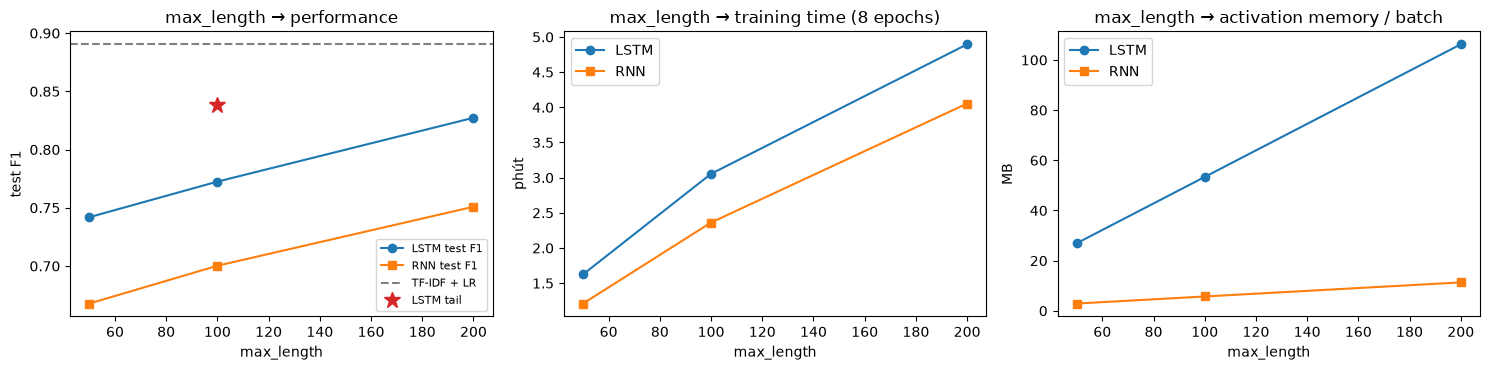

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for t, mk in [("LSTM", "o-"), ("RNN", "s-")]:
    d = seq_df[(seq_df.model == t) & (seq_df.truncation == "head")]
    axes[0].plot(d.max_length, d.f1, mk, label=f"{t} test F1")
    axes[1].plot(d.max_length, d.train_time_s / 60, mk, label=t)
    axes[2].plot(d.max_length, d.activation_MB_per_batch, mk, label=t)
axes[0].axhline(m_base["f1"], color="gray", ls="--", label="TF-IDF + LR")
d = seq_df[seq_df.truncation == "tail"]
axes[0].plot(d.max_length, d.f1, "*", ms=12, color="tab:red", label="LSTM tail")
axes[0].set(title="max_length → performance", xlabel="max_length", ylabel="test F1"); axes[0].legend(fontsize=8)
axes[1].set(title=f"max_length → training time ({EPOCHS} epochs)", xlabel="max_length", ylabel="phút"); axes[1].legend()
axes[2].set(title="max_length → activation memory / batch", xlabel="max_length", ylabel="MB"); axes[2].legend()
plt.tight_layout()
plt.savefig("sequence_length.png", dpi=120)
plt.show()

In [19]:
# Độ chính xác theo độ dài review (LSTM, test): review bị cắt vs không bị cắt
bins = [0, 50, 100, 200, 400, 10**5]
labels = ["≤50", "51-100", "101-200", "201-400", ">400"]
bucket = pd.cut(len_test, bins=bins, labels=labels)
acc_by_len = {}
for t in ["RNN", "LSTM", "GRU"]:
    acc_by_len[f"{t} L=200"] = pd.Series((test_proba[t] >= 0.5) == y_test).groupby(bucket, observed=True).mean()
acc_by_len["TF-IDF + LR (full)"] = pd.Series((p_base >= 0.5) == y_test).groupby(bucket, observed=True).mean()
acc_by_len = pd.DataFrame(acc_by_len)
acc_by_len.insert(0, "n_reviews", pd.Series(bucket).value_counts().reindex(labels).values)
for b, r in acc_by_len.iterrows():
    for k, v in r.items():
        log("exp5_acc_by_length", k, b, "test", "accuracy" if k != "n_reviews" else "n_reviews", v)
acc_by_len.round(4)

,n_reviews,RNN L=200,LSTM L=200,GRU L=200,TF-IDF + LR (full)
≤50,635,0.8315,0.8772,0.8819,0.8913
51-100,2485,0.8133,0.8652,0.8748,0.8942
101-200,11603,0.7795,0.8606,0.8796,0.8900
201-400,6887,0.7118,0.7854,0.8266,0.8883
>400,3068,0.6555,0.7324,0.7578,0.8892


**Tăng max_length có luôn cải thiện performance không?** Trong khoảng 50 - 200 thì có: F1 của LSTM 0.742 → 0.773 → 0.827, của RNN 0.668 → 0.700 → 0.751. Tuy vậy:

- **Thông tin nằm ở đâu quan trọng hơn độ dài.** LSTM giữ **100 token cuối** (tail) đạt F1 0.838, cao hơn LSTM giữ 200 token đầu (0.827), với một nửa số token và ít thời gian hơn (189 s so với 294 s). Kết luận của review (điểm số, "recommended", "avoid") thường ở cuối.
- RNN vẫn tốt lên khi tăng L, dù gradient tới token xa gần như bằng 0 (mục 8). Cách giải thích hợp lý: với L = 200, 59.7% review test không bị cắt, nên phần cuối thật của review nằm ngay trước h_T. Với L = 50 chỉ 2.6% review được giữ nguyên, model chỉ thấy phần mở đầu. Tức RNN không dùng được context dài hơn, mà được lợi vì phần cuối review được đưa vào.
- Theo độ dài review, accuracy giảm mạnh khi review dài: GRU 0.882 (≤ 50 token) → 0.758 (> 400 token), RNN 0.832 → 0.656. TF-IDF dùng toàn bộ review nên ổn định ở khoảng 0.89 cho mọi nhóm. Với review ≤ 200 token (không bị cắt), GRU (0.875 - 0.882) gần bằng TF-IDF (0.890 - 0.894). Khoảng cách tổng thể đến chủ yếu từ review dài. RNN giảm cả ở các nhóm không bị cắt (0.832 → 0.780), là dấu hiệu khó nhớ context dài.

**Nếu max_length quá nhỏ, mất thông tin gì?** Phần kết luận và đánh giá tổng thể ở cuối review, các đoạn đảo chiều sau "but", "however", và với L = 50 thì gần như chỉ còn phần giới thiệu, tóm tắt cốt truyện (trung tính).

**Trade-off giữa context và computational cost:** có. Từ 50 lên 200 (×4): thời gian mỗi epoch của LSTM tăng 11.8 → 34.9 s (×3.0), RNN 8.9 → 29.6 s (×3.3). Activation memory mỗi batch tăng đúng tuyến tính: LSTM 26.9 → 106.3 MB (×3.9), RNN 2.9 → 11.3 MB. LSTM tốn gấp khoảng 9 lần RNN vì lưu 4 gate và cell state ở mỗi timestep. RNN không song song được theo thời gian: bước t phải chờ bước t - 1.

## 8. Experiment 6 - Long-range dependency

Câu quyết định sentiment ("the movie was ultimately excellent / terrible", ...) được đặt ở **đầu**, **giữa** hoặc **cuối** một đoạn filler trung tính (mô tả cốt truyện, thông tin sản xuất). Tổng độ dài được giữ dưới 200 token để không bị truncate. Đo P(pos) của bản positive và bản negative, và **separation** = P(pos | bản positive) - P(pos | bản negative). Separation gần 1 nghĩa là model nhận ra từ khoá, gần 0 nghĩa là model không phân biệt được.

TF-IDF + LR là đối chứng: bag-of-words không phụ thuộc vị trí nên separation giống nhau ở mọi vị trí.

In [20]:
print("Ví dụ trong đề:")
ex = ["The movie was, despite many unnecessary scenes, ultimately excellent.",
      "The movie was, despite many unnecessary scenes, ultimately terrible."]
print(pd.DataFrame({t: proba_texts(m, ex) for t, m in models.items()} | {"TF-IDF+LR": baseline.predict_proba(ex)[:, 1]},
                   index=["... excellent", "... terrible"]).round(3))

FILLER = [
    "the film was shot in a small town in the north of the country during the winter of that year .",
    "it runs for about two hours and was released in theaters in the spring .",
    "the story follows a man who moves back to his home town after many years away .",
    "he takes a job at the local school and meets some of the people he grew up with .",
    "his sister works at the hospital and his father still runs the family store on the main street .",
    "most of the scenes take place in the house , the school and the store .",
    "the cast includes several actors who also appeared in the director 's previous film .",
    "the music was written by a composer who has worked on many television series .",
    "there is also a second story about a young woman who is looking for her brother .",
    "the two stories meet in the last part of the film when the town holds its annual festival .",
    "the dvd includes a commentary track and a short documentary about the production .",
    "i watched it on a sunday afternoon with two friends .",
]
KEY_PAIRS = [
    ("the movie was ultimately excellent .", "the movie was ultimately terrible ."),
    ("overall it is a great film .", "overall it is an awful film ."),
    ("i loved every minute of it .", "i hated every minute of it ."),
    ("the acting was wonderful .", "the acting was horrible ."),
    ("highly recommended .", "a complete waste of time ."),
]

def build(key, n_filler, position, seed):
    r = np.random.default_rng(seed)
    filler = list(r.choice(FILLER, size=n_filler, replace=n_filler > len(FILLER)))
    pos = {"beginning": 0, "middle": n_filler // 2, "end": n_filler}[position]
    return " ".join(filler[:pos] + [key] + filler[pos:])

long_rows = []
for n_filler in [2, 6, 10]:
    for position in ["beginning", "middle", "end"]:
        texts_pos, texts_neg = [], []
        for k, (kp, kn) in enumerate(KEY_PAIRS):
            for s in range(4):                              # 4 cách chọn filler khác nhau
                texts_pos.append(build(kp, n_filler, position, seed=100 * k + s))
                texts_neg.append(build(kn, n_filler, position, seed=100 * k + s))
        n_tok = np.mean([len(preprocess(x)) for x in texts_pos])
        assert max(len(preprocess(x)) for x in texts_pos + texts_neg) <= MAX_LEN
        scorers = {t: (lambda x, m=m: proba_texts(m, x)) for t, m in models.items()}
        scorers["TF-IDF+LR"] = lambda x: baseline.predict_proba(x)[:, 1]
        for name, f in scorers.items():
            pp, pn = f(texts_pos), f(texts_neg)
            long_rows.append({"filler_sentences": n_filler, "avg_tokens": n_tok, "position": position, "model": name,
                              "P(pos|pos)": pp.mean(), "P(pos|neg)": pn.mean(), "separation": (pp - pn).mean(),
                              "accuracy": ((pp >= 0.5).sum() + (pn < 0.5).sum()) / (len(pp) + len(pn))})
long_df = pd.DataFrame(long_rows)
for _, r in long_df.iterrows():
    for k in ["separation", "accuracy", "P(pos|pos)", "P(pos|neg)"]:
        log("exp6_long_range", r["model"], f"filler={r['filler_sentences']} {r['position']}", "-", k, r[k])
print("Ví dụ (filler = 6, middle):", build(KEY_PAIRS[0][0], 6, "middle", seed=0))
long_df.pivot_table(index=["filler_sentences", "avg_tokens"], columns=["model", "position"], values="separation").round(3)

Ví dụ trong đề:
                 RNN   LSTM    GRU  TF-IDF+LR
... excellent  0.390  0.683  0.618      0.719
... terrible   0.102  0.087  0.086      0.014


Ví dụ (filler = 6, middle): the story follows a man who moves back to his home town after many years away . the music was written by a composer who has worked on many television series . his sister works at the hospital and his father still runs the family store on the main street . the movie was ultimately excellent . he takes a job at the local school and meets some of the people he grew up with . the film was shot in a small town in the north of the country during the winter of that year . most of the scenes take place in the house , the school and the store .


model                             GRU                    LSTM                \
position                    beginning    end middle beginning    end middle   
filler_sentences avg_tokens                                                   
2                36.85          0.468  0.415  0.331     0.297  0.510  0.269   
6                98.95          0.103  0.211  0.052     0.003  0.413  0.004   
10               159.15         0.021  0.126  0.012     0.000  0.396  0.000   

model                             RNN               TF-IDF+LR                
position                    beginning    end middle beginning    end middle  
filler_sentences avg_tokens                                                  
2                36.85          0.233  0.448  0.234     0.379  0.379  0.379  
6                98.95          0.000  0.452  0.094     0.085  0.085  0.085  
10               159.15        -0.000  0.466  0.000     0.038  0.038  0.038

In [21]:
long_df.pivot_table(index=["filler_sentences"], columns=["model", "position"], values="accuracy").round(3)

model                  GRU                    LSTM                     RNN  \
position         beginning    end middle beginning    end middle beginning   
filler_sentences                                                             
2                    0.775  0.725  0.675       0.7  0.800  0.675     0.675   
6                    0.525  0.500  0.500       0.5  0.750  0.500     0.500   
10                   0.500  0.500  0.500       0.5  0.675  0.500     0.500   

model                          TF-IDF+LR                
position            end middle beginning    end middle  
filler_sentences                                        
2                 0.825    0.7     0.725  0.725  0.725  
6                 0.800    0.6     0.500  0.500  0.500  
10                0.850    0.5     0.500  0.500  0.500

### Gradient theo vị trí token

Kiểm tra trực tiếp trên các model đã train: với 200 review test dài ≥ 200 token (cắt còn 200), tính ‖∂z/∂e_t‖, độ lớn gradient của logit z theo embedding của token ở vị trí t. Đây là thước đo "token ở vị trí t còn ảnh hưởng tới output bao nhiêu" (sensitivity), liên quan nhưng không đồng nhất với gradient khi train (∂L/∂W).

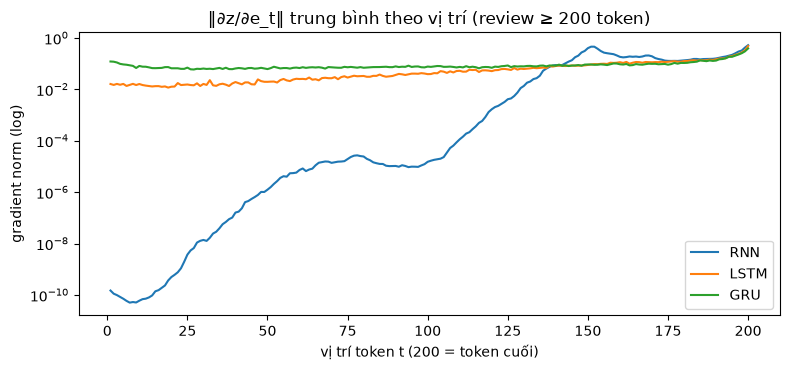

,RNN,LSTM,GRU
position,,,
t=1 / t=200,0.000000,0.033324,0.310382
t=50 / t=200,0.000002,0.040484,0.157295
t=100 / t=200,0.000029,0.080518,0.196917
t=150 / t=200,0.768804,0.183907,0.237379
t=190 / t=200,0.305471,0.305912,0.337007
t=200 / t=200,1.000000,1.000000,1.000000


In [22]:
long_idx = np.where(len_test >= MAX_LEN)[0][:200]
ids_long, lens_long = to_tensors([ids_test[i] for i in long_idx], MAX_LEN)
grad_pos = {}
for t, m in models.items():
    m.eval()
    e = m.emb(ids_long).detach().requires_grad_(True)
    m.forward_embedded(e, lens_long).sum().backward()
    grad_pos[t] = e.grad.norm(dim=2).mean(0).numpy()      # trung bình trên 200 review, theo vị trí
grad_df = pd.DataFrame(grad_pos, index=np.arange(1, MAX_LEN + 1))
grad_df.index.name = "position"
fig, ax = plt.subplots(figsize=(8, 3.8))
for t in grad_df:
    ax.semilogy(grad_df.index, grad_df[t], label=t)
ax.set(title="‖∂z/∂e_t‖ trung bình theo vị trí (review ≥ 200 token)", xlabel="vị trí token t (200 = token cuối)",
       ylabel="gradient norm (log)")
ax.legend()
plt.tight_layout()
plt.savefig("gradient_by_position.png", dpi=120)
plt.show()
ratio = grad_df.loc[[1, 50, 100, 150, 190, 200]]
for t in grad_df:
    for pos, v in ratio[t].items():
        log("exp6_gradient", t, f"position={pos}", "test", "grad_norm", v)
(ratio / grad_df.loc[200]).round(6).rename(lambda p: f"t={p} / t=200")

**Quan sát thực nghiệm (empirical observation):**

- Khi câu quyết định nằm ở **cuối**, LSTM và RNN vẫn nhận ra dù filler dài: separation của LSTM 0.51 / 0.41 / 0.40 với khoảng 37 / 99 / 159 token, RNN khoảng 0.45 ở cả ba độ dài.
- Khi câu quyết định nằm ở **đầu hoặc giữa**, separation giảm nhanh theo độ dài filler: LSTM 0.30 → 0.003 → 0.000 (đầu), RNN 0.23 → 0.000 → 0.000. Với khoảng 100 token phía sau, gần như không model nào còn phân biệt được bản "excellent" với bản "terrible". GRU giữ được lâu hơn một chút (đầu: 0.47 → 0.10 → 0.02), nhưng ngay cả ở cuối GRU cũng giảm (0.42 → 0.13).
- TF-IDF + LR không phụ thuộc vị trí (giống nhau ở cả ba vị trí), nhưng separation cũng giảm theo độ dài (0.38 → 0.04) vì từ khoá bị pha loãng trong vector đã chuẩn hoá. Hiệu ứng vị trí chỉ xuất hiện ở sequence model.
- Ví dụ trong đề: "... ultimately excellent" có P(pos) = 0.683 (LSTM), 0.618 (GRU), nhưng RNN chỉ 0.390 (sai). Bản "terrible" thì cả ba model đều đúng (≤ 0.10).

**Gradient theo vị trí:** với RNN, ‖∂z/∂e_t‖ giảm theo hàm mũ khi đi ngược từ token cuối: ở t = 100 chỉ còn khoảng 3·10⁻⁵ lần so với t = 200, ở t = 1 xuống khoảng 10⁻¹⁰. Đây đúng là tích các Jacobian co lại trong lý thuyết. Với LSTM, tỉ lệ ở t = 1 vẫn khoảng 0.03, và với GRU khoảng 0.3, gần như phẳng. Hình `gradient_by_position.png`.

**Giải thích lý thuyết (theoretical explanation) và giới hạn của kết luận:** đường gradient của RNN phù hợp với lập luận $\partial h_T/\partial h_t = \prod \operatorname{diag}(1-h_k^2)W_{hh}$ co về 0, còn cell state của LSTM và update gate của GRU tạo đường đi gần như "cộng" nên tín hiệu không bị co lại nhiều. Tuy vậy, thí nghiệm nhỏ này **không chứng minh** vanishing gradient:

- Gradient ở đây là sensitivity của output theo input của model đã train xong, không phải gradient lúc train theo từng bước.
- LSTM có gradient tới token đầu không nhỏ (0.03) nhưng separation ở đầu vẫn bằng 0. Nghĩa là "có đường truyền gradient" khác với "model đã học để giữ thông tin đó". Model được train trên review thật, nơi tín hiệu cuối review thường đủ để đoán, nên nó không có động lực học cách nhớ phần đầu.
- Filler nhân tạo có thể tự mang chút sentiment (ví dụ GRU nghiêng về một class), và chỉ có 20 cặp câu cho mỗi ô.

## 9. Evaluation

Positive class = positive (label 1). Bảng cuối trên test, kèm chi phí tính toán.

In [23]:
final_rows = [{"model": "TF-IDF + LR", "representation": "TF-IDF unigram (sparse)", **m_base,
               "params": base_params, "train_time_s": base_time, "epochs": "-", "sequence_length": "full",
               "vocab_size": base_vocab}]
for t in models:
    final_rows.append({"model": t, "representation": "Embedding 100 (dense, học cùng model)", **test_metrics[t],
                       "params": infos[t]["params_total"], "train_time_s": infos[t]["train_time_s"],
                       "epochs": f"{EPOCHS} (best {infos[t]['best_epoch']})", "sequence_length": MAX_LEN,
                       "vocab_size": VOCAB_SIZE})
final = pd.DataFrame(final_rows).set_index("model")
for name, r in final.iterrows():
    for k in ["accuracy", "precision", "recall", "f1"]:
        log("evaluation", name, "final", "test", k, r[k])
final.round(4)

,representation,accuracy,precision,recall,f1,params,train_time_s,epochs,sequence_length,vocab_size
model,,,,,,,,,,
TF-IDF + LR,TF-IDF unigram (sparse),0.8899,0.8915,0.8894,0.8904,43173,3.6436,-,full,43172
RNN,"Embedding 100 (dense, học cùng model)",0.7499,0.7524,0.7494,0.7509,2029769,243.2427,8 (best 5),200,20002
LSTM,"Embedding 100 (dense, học cùng model)",0.8246,0.8194,0.8354,0.8273,2118089,293.7533,8 (best 5),200,20002
GRU,"Embedding 100 (dense, học cùng model)",0.8493,0.8310,0.8790,0.8543,2088649,776.0531,8 (best 4),200,20002


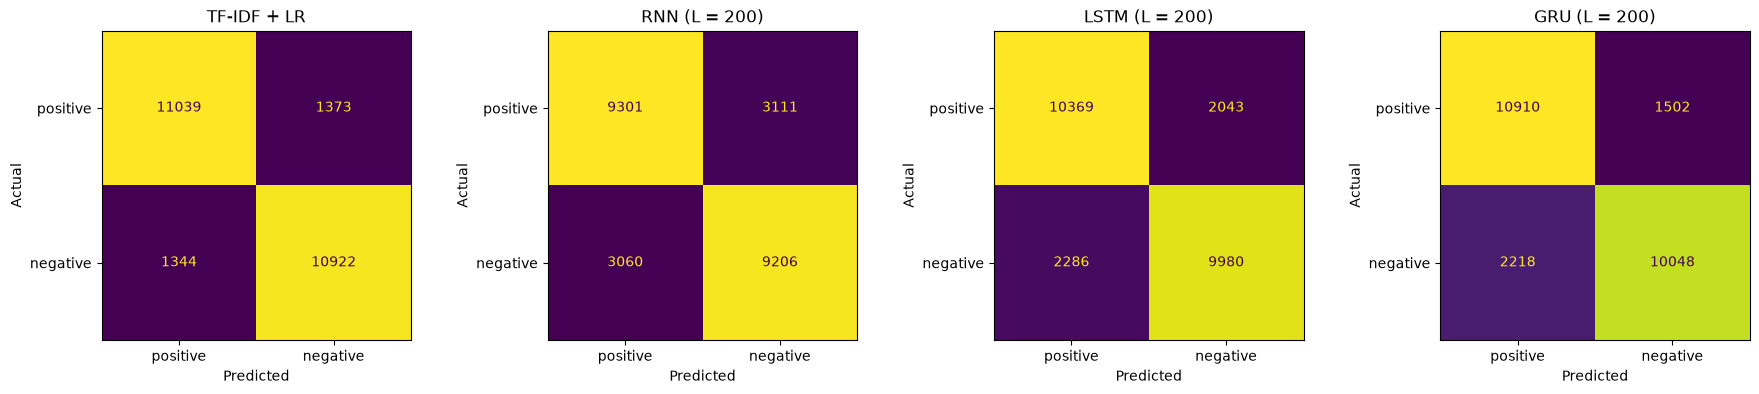

,TP,FN,FP,TN
model,,,,
TF-IDF + LR,11039,1373,1344,10922
RNN,9301,3111,3060,9206
LSTM,10369,2043,2286,9980
GRU,10910,1502,2218,10048


In [24]:
preds = {"TF-IDF + LR": (p_base >= 0.5).astype(int)} | {t: (test_proba[t] >= 0.5).astype(int) for t in models}
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
cm_rows = []
for ax, (name, p) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, p, labels=[1, 0])          # hàng = actual, cột = predicted
    ConfusionMatrixDisplay(cm, display_labels=["positive", "negative"]).plot(ax=ax, colorbar=False, values_format="d")
    ax.set(title=name if name == "TF-IDF + LR" else f"{name} (L = {MAX_LEN})", xlabel="Predicted", ylabel="Actual")
    tp, fn, fp, tn = cm.ravel()
    cm_rows.append({"model": name, "TP": tp, "FN": fn, "FP": fp, "TN": tn})
    for k, v in cm_rows[-1].items():
        if k != "model":
            log("evaluation", name, "confusion_matrix", "test", k, v)
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=120)
plt.show()
pd.DataFrame(cm_rows).set_index("model")

- TF-IDF + LR vẫn là model tốt nhất (F1 0.890), lại nhỏ nhất (43K tham số) và nhanh nhất (3.6 s). Trong các sequence model: GRU 0.854 > LSTM 0.827 > RNN 0.751.
- Confusion matrix: RNN nhầm nhiều và đều ở hai class (FN 3,111, FP 3,060). LSTM có FP 2,286 > FN 2,043. GRU lệch rõ về positive (FP 2,218 so với FN 1,502), nên recall 0.879 cao hơn precision 0.831.
- Không thể đánh giá model chỉ bằng accuracy: GRU tốn khoảng 13 phút train, gấp khoảng 200 lần TF-IDF, cần chọn max_length và số epoch, và vẫn kém hơn 3.6 điểm F1. Lợi thế của sequence model (thứ tự, phủ định cục bộ) chỉ thấy rõ ở câu ngắn (mục 6, mục 11).

## 10. Error analysis

Model phân tích: model sequence có validation F1 cao nhất. Để giải thích từng prediction dùng **occlusion**: bỏ lần lượt từng token và xem P(pos) thay đổi bao nhiêu, Δ = P(pos | review) - P(pos | review bỏ token đó). Δ > 0: token đẩy về positive.

In [25]:
best_name = max(models, key=lambda t: histories[t].loc[infos[t]["best_epoch"] - 1, "val_f1"])
best_model = models[best_name]
print("Model phân tích:", best_name)

def occlusion(model, text, L=MAX_LEN, k=6):
    toks = preprocess(text)[:L]
    ids = encode(toks)
    variants = [ids] + [ids[:i] + ids[i + 1:] for i in range(len(ids))]
    X, lens = to_tensors(variants, L)
    p = predict_proba(model, X, lens)
    delta = p[0] - p[1:]
    order = np.argsort(delta)
    fmt = lambda i: (toks[i] + ("@" + str(i)), round(float(delta[i]), 3))
    return p[0], [fmt(i) for i in order[::-1][:k] if delta[i] > 0], [fmt(i) for i in order[:k] if delta[i] < 0]

ea = test_df.assign(pred=preds[best_name], p_pos=test_proba[best_name], p_base=p_base,
                    pred_base=preds["TF-IDF + LR"], n_tokens=len_test)
for t in models:
    ea[f"p_{t}"] = test_proba[t]
ea["correct"] = ea["pred"] == ea["label"]
ea["truncated"] = ea["n_tokens"] > MAX_LEN
clean = ea["text"].map(lambda t: " ".join(preprocess(t)))
ea["has_negation"] = clean.str.contains(r"\b(?:not|no|never|isn't|wasn't|don't|doesn't|didn't)\b")
ea["has_contrast"] = clean.str.contains(r"\b(?:but|however|although|though|yet)\b")
summary = ea.groupby("correct").agg(n=("label", "size"), median_tokens=("n_tokens", "median"),
                                    truncated_rate=("truncated", "mean"), negation_rate=("has_negation", "mean"),
                                    contrast_rate=("has_contrast", "mean"),
                                    mean_confidence=("p_pos", lambda p: np.maximum(p, 1 - p).mean()))
for c, r in summary.iterrows():
    for k, v in r.items():
        log("error_analysis", best_name, f"correct={c}", "test", k, v)
summary.round(3)

Model phân tích: GRU


,n,median_tokens,truncated_rate,negation_rate,contrast_rate,mean_confidence
correct,,,,,,
False,3720,210.0,0.521,0.877,0.853,0.784
True,20958,168.0,0.383,0.835,0.780,0.917


In [26]:
both = pd.crosstab(ea["correct"].map({True: f"{best_name} đúng", False: f"{best_name} sai"}),
                   (ea["pred_base"] == ea["label"]).map({True: "TF-IDF đúng", False: "TF-IDF sai"}))
both

col_0,TF-IDF sai,TF-IDF đúng
correct,,
GRU sai,1703,2017
GRU đúng,1014,19944


In [27]:
short = ea[ea["n_tokens"].between(15, 120)].assign(conf=lambda d: (d["p_pos"] - 0.5).abs())
cols = ["text", "label", "pred", "p_pos", "p_base"] + [f"p_{t}" for t in models]
print("Đúng, tự tin cao:")
display(pd.concat([short[short.correct & (short.label == 1)].nlargest(3, "conf"),
                   short[short.correct & (short.label == 0)].nlargest(3, "conf")])[cols].round(3))
print("Sai, tự tin cao:")
wrong = short[~short.correct].sort_values("conf", ascending=False)
display(pd.concat([wrong[wrong.label == 0].head(6), wrong[wrong.label == 1].head(6)])[cols].round(3))

Đúng, tự tin cao:


,text,label,pred,p_pos,p_base,p_RNN,p_LSTM,p_GRU
21881,"I have to say that I haven't expected that this movie to be this good. Usually, the eastern cinema presents the communist past in 90% of the films. However, this film surpasses the Romanian Cinema...",1,1,0.998,0.973,0.938,0.998,0.998
19415,"I was pleasantly surprised by how good the movie was. Whether you're a gore fan or a suspense fan; you'll love this. I used to dislike horror movies, considered them stupid. But, anyway, it happen...",1,1,0.997,0.968,0.956,0.985,0.997
20357,"OK, I don't kid myself that this is the typical gay love life but since when are straight romances in real life as they are on the screen? This movie is well-balanced with comedy and drama and I t...",1,1,0.997,0.930,0.946,0.994,0.997
11121,"Dude...I liked Buffy and Angel as much as the next sci-fi freak...but this is too much. The worst lead actress EVER!! Not even David ""Hot Pants"" Boreanaz is able to save this crap. No wonder I NEV...",0,0,0.001,0.003,0.047,0.004,0.001
2831,"Yet again not quite bad enough to make it enjoyable. In fact this one is just boring. It's reasonably well made, even though the script is bad, the effects are OK and the acting average. (Apart fr...",0,0,0.001,0.004,0.054,0.006,0.001
3255,"A friend of mine decided to rent this thing, lucky it wasn't my money.. Pretty much wasted my time though. A story that could have been interesting is completely wasted by incredibly bad acting an...",0,0,0.002,0.001,0.057,0.002,0.002


Sai, tự tin cao:


,text,label,pred,p_pos,p_base,p_RNN,p_LSTM,p_GRU
11859,"This movie was pure genius. John Waters is brilliant. It is hilarious and I am not sick of it even after seeing it about 20 times since I bought it a few months ago. The acting is great, although ...",0,1,0.996,0.996,0.956,0.990,0.996
2647,"I really liked this quirky movie. The characters are not the bland beautiful people that show up in so many movies and on TV. It has a realistic edge, with a captivating story line. The main title...",0,1,0.990,0.982,0.826,0.979,0.990
10170,"I don't really know why so many persons love this movie: maybe it's funny, OK, but it has totally ruined one of the best novels ever written. As the author himself said, this movie has betrayed th...",0,1,0.990,0.824,0.901,0.979,0.990
4020,This is definitely one of the best Kung fu movies in the history of Cinema. The screenplay is really well done (which is not often the case for this type of movies) and you can see that Chuck (in ...,0,1,0.986,0.995,0.868,0.953,0.986
3827,"This is definitely one of the weaker of the series of Carry On films. It lacks the usual fun and sparkle and even the cast seem embarrassed by the poor dialogue. By the time this came out, the ser...",0,1,0.985,0.204,0.871,0.878,0.985
6412,"Masterpiece. Carrot Top blows the screen away. Never has one movie captured the essence of the human spirit quite like ""Chairman of the Board."" 10/10... don't miss this instant classic.",0,1,0.984,0.964,0.944,0.944,0.984
14830,"Just want to inform you guys that this movie was actually pretty good !!! <br /><br />Thought it was a lame ass movie, but not at all, many moments in this movie wore pretty horrifying. <br /><br ...",1,0,0.013,0.480,0.225,0.090,0.013
22004,This is just my all time favorite movie. Nothing special. It's just so incredibly detailed. Makes me cry just thinking about it. Geronimo Bill is the nicest guy I can imagine. Money is not importa...,1,0,0.014,0.172,0.071,0.016,0.014
12487,"Three children are born at the exact same time,during a lunar eclipse.Just before their 10th birthday they embark on a killing spree.""Bloody Birthday"" is a typical slasher from early 80's.It's a p...",1,0,0.015,0.106,0.128,0.057,0.015
24087,"ALICE is the kind of movie they made in the 30's and 40's. Never attempts to be an ""event"". Just wants to entertain. And it does. I was surprised by Kiefer Sutherland. In a role that could be a cl...",1,0,0.021,0.544,0.113,0.191,0.021


In [28]:
# Sai nhưng TF-IDF đúng: các trường hợp sequence model làm hỏng
seq_only = ea[~ea.correct & (ea.pred_base == ea.label) & ea.n_tokens.between(15, 200)]
seq_only = seq_only.assign(conf=lambda d: (d["p_pos"] - 0.5).abs()).sort_values("conf", ascending=False)
display(seq_only.head(6)[cols].round(3))
# Sai ở review bị truncate
trunc_wrong = ea[~ea.correct & ea.truncated].assign(conf=lambda d: (d["p_pos"] - 0.5).abs()).sort_values("conf", ascending=False)
print("Review bị cắt mà model sai:", len(trunc_wrong), "/", ea.truncated.sum())
for i, r in trunc_wrong.head(3).iterrows():
    toks = preprocess(r.text)
    print(f"\n#{i} true={LABEL_NAMES[r.label]} p_pos={r.p_pos:.3f} p_base={r.p_base:.3f} tokens={len(toks)}")
    print("  200 token đầu (model thấy):", " ".join(toks[:60]), "...")
    print("  phần bị cắt, 60 token cuối:", " ".join(toks[-60:]))

,text,label,pred,p_pos,p_base,p_RNN,p_LSTM,p_GRU
16758,This movie deserved better. Mike Judge's satirical wit brought to light something too many in this country are trying to deny... we're getting dumber as a society.<br /><br />Could the 24-hour-a-d...,1,0,0.011,0.510,0.107,0.020,0.011
3827,"This is definitely one of the weaker of the series of Carry On films. It lacks the usual fun and sparkle and even the cast seem embarrassed by the poor dialogue. By the time this came out, the ser...",0,1,0.985,0.204,0.871,0.878,0.985
24087,"ALICE is the kind of movie they made in the 30's and 40's. Never attempts to be an ""event"". Just wants to entertain. And it does. I was surprised by Kiefer Sutherland. In a role that could be a cl...",1,0,0.021,0.544,0.113,0.191,0.021
11285,"I was told Jon was for awhile on spiritual experiences. I guessed the film will be interesting.In fact isn't at all. Not so much profound for a such subject. ""eternity"" never-ending life. Experien...",0,1,0.977,0.493,0.787,0.955,0.977
13517,"Walter Matthau and Jack Lemmon, both of whom are sadly missed, proved once again that they were a team dedicated to their craft of bringing hilarious moments to the screen. This film is just anoth...",1,0,0.024,0.594,0.343,0.062,0.024
676,"Of all of the post-1985 Perry Mason movies I have seen, this one is my least favorite.<br /><br />I confess I have never liked Diana Muldaur as an actress. She only seems to know how to play one t...",0,1,0.971,0.361,0.882,0.957,0.971


Review bị cắt mà model sai: 1937 / 9955

#19553 true=positive p_pos=0.004 p_base=0.160 tokens=219
  200 token đầu (model thấy): okay i'll say it this movie made me laugh so hard that it hurt this statement may offend some of you who may think that this movie is nothing more than a waste of film but the thing that most people don't get is that this movie was intended to be bad and cheezy i mean did people actually think ...
  phần bị cắt, 60 token cuối: of dialogue doesn't make you laugh then you have serious issues who in their right mind would utter those words in real life of course no one because it was meant to sound ridiculous just take one viewing of this movie with an open mind and low expectations and hopefully you'll see what's so damn funny about jack frost 2

#23571 true=positive p_pos=0.005 p_base=0.189 tokens=398
  200 token đầu (model thấy): i want to preface this review by saying that i have no idea what begotten is truly about all i really know is that in the beginning 

In [29]:
cases = pd.concat([short[short.correct & (short.label == 1)].nlargest(3, "conf"),
                   short[short.correct & (short.label == 0)].nlargest(3, "conf"),
                   wrong[wrong.label == 0].head(6), wrong[wrong.label == 1].head(6), seq_only.head(6)])
for i, r in cases.iterrows():
    p, pos, neg = occlusion(best_model, r.text)
    print(f"#{i} true={LABEL_NAMES[r.label]} pred={LABEL_NAMES[r.pred]} P(pos)={p:.3f} | + {pos} | - {neg}")

#21881 true=positive pred=positive P(pos)=0.998 | + [('7@117', 0.002), ('10@118', 0.001), ('enjoy@115', 0.0), ('watch@110', 0.0), ('definitely@114', 0.0), ('cinema@34', 0.0)] | - [('adventure@106', -0.0), ('to@11', -0.0), ('have@94', -0.0), ('for@105', -0.0), ('will@113', -0.0), ('exaggerated@47', -0.0)]


#19415 true=positive pred=positive P(pos)=0.997 | + [('enjoy@109', 0.003), ('recommend@108', 0.001), ('movies@104', 0.0), ('highly@89', 0.0), ('glad@95', 0.0), ('this@79', 0.0)] | - [('these@105', -0.0), ("i'm@94", -0.0), ('development@84', -0.0), ('that@96', -0.0), ('horror@77', -0.0), ('crap@57', -0.0)]


#20357 true=positive pred=positive P(pos)=0.997 | + [('8@114', 0.004), ('thumbs@112', 0.001), ('10@115', 0.001), ('weaving@49', 0.0), ('hoot@111', 0.0), ('well@31', 0.0)] | - [('up@113', -0.0), ('male@106', -0.0), ('were@109', -0.0), ('balanced@32', -0.0), ('gay@54', -0.0), ('to@46', -0.0)]
#11121 true=negative pred=negative P(pos)=0.001 | + [('sockets@111', 0.0), ('show@100', 0.0), ('when@105', 0.0), ('eyes@107', 0.0), ('it@104', 0.0), ('too@17', 0.0)] | - [('worst@20', -0.001), ('crap@113', -0.0), ('crap@112', -0.0), ('crap@114', -0.0), ('from@109', -0.0), ('waste@95', -0.0)]


#2831 true=negative pred=negative P(pos)=0.001 | + [('ever@69', 0.0), ('well@19', 0.0), ('great@42', 0.0), ('it@60', 0.0), ('it@50', 0.0), ('film@58', 0.0)] | - [('boring@16', -0.001), ('dull@73', -0.0), ('dull@71', -0.0), ('dull@74', -0.0), ('dull@72', -0.0), ('dull@70', -0.0)]


#3255 true=negative pred=negative P(pos)=0.002 | + [('and@97', 0.0), ('classic@43', 0.0), ('grabbed@75', 0.0), ('to@5', 0.0), ('reasons@82', 0.0), ('attention@77', 0.0)] | - [('10@100', -0.001), ('waste@94', -0.001), ('2@99', -0.0), ('money@98', -0.0), ('a@93', -0.0), ('bad@32', -0.0)]


...

#19601 true=positive pred=negative P(pos)=0.025 | + [('you@56', 0.008), ('low@0', 0.004), ('liked@46', 0.004), ('is@52', 0.003), ('seat@33', 0.003), ('as@34', 0.002)] | - [('campy@10', -0.016), ("80's@48", -0.012), ('name@4', -0.011), ('budget@1', -0.007), ('for@55', -0.007), ('mostly@2', -0.006)]


#13467 true=positive pred=negative P(pos)=0.027 | + [('solid@108', 0.014), ('it@105', 0.005), ('good@0', 0.005), ('well@65', 0.005), ('a@107', 0.005), ('it@98', 0.004)] | - [('boring@1', -0.026), ('bad@3', -0.025), ('onto@106', -0.013), ('money@8', -0.007), ('opportunity@46', -0.007), ('ripoff@80', -0.005)]
#16758 true=positive pred=negative P(pos)=0.011 | + [('release@110', 0.003), ('with@113', 0.003), ('that@119', 0.001), ('film@112', 0.001), ('day@32', 0.001), ('taking@124', 0.001)] | - [('zero@114', -0.013), ('promotion@115', -0.011), ('stupid@121', -0.008), ('deserved@2', -0.003), ('this@111', -0.002), ('better@3', -0.001)]


#3827 true=negative pred=positive P(pos)=0.985 | + [('end@61', 0.007), ('near@59', 0.004), ('this@0', 0.003), ('series@54', 0.003), ('definitely@2', 0.003), ('one@3', 0.002)] | - [('the@60', -0.004), ('avoid@55', -0.002), ('poor@29', -0.002), ('in@40', -0.001), ('lacks@15', -0.001), ('till@58', -0.001)]


#24087 true=positive pred=negative P(pos)=0.021 | + [('loved@88', 0.005), ('very@94', 0.005), ('wants@20', 0.003), ('you@81', 0.003), ('surprised@28', 0.003), ('the@89', 0.003)] | - [('interesting@98', -0.035), ('freshness@80', -0.013), ('plot@45', -0.01), ('just@92', -0.009), ('alice@0', -0.007), ('allusions@48', -0.004)]
#11285 true=negative pred=positive P(pos)=0.977 | + [('profound@140', 0.014), ('it@142', 0.011), ('best@95', 0.007), ('launched@109', 0.007), ('to@66', 0.004), ('normal@96', 0.004)] | - [('screenwriter@102', -0.004), ("isn't@137", -0.003), ('producer@100', -0.002), ('video@112', -0.002), ('much@139', -0.002), ('naive@62', -0.001)]


#13517 true=positive pred=negative P(pos)=0.024 | + [('tribute@176', 0.01), ('matthau@1', 0.009), ('jack@3', 0.008), ('again@13', 0.006), ('another@34', 0.005), ('time@39', 0.005)] | - [('sadly@9', -0.179), ('example@35', -0.073), ('just@33', -0.07), ('bad@103', -0.015), ('illustrious@179', -0.012), ('careers@180', -0.011)]
#676 true=negative pred=positive P(pos)=0.971 | + [('alone@113', 0.03), ('true@73', 0.027), ('worth@109', 0.021), ('favorite@17', 0.011), ('exception@70', 0.009), ('runs@72', 0.007)] | - [('earnest@88', -0.01), ('no@69', -0.008), ('least@16', -0.006), ('for@111', -0.006), ('scott@91', -0.004), ('opinion@85', -0.004)]


Tóm tắt (chi tiết ở `error_analysis.md`):

- Review GRU đoán sai dài hơn (median 210 token so với 168), bị cắt nhiều hơn (52% so với 38%). Tỉ lệ lỗi là 19.5% trên review bị cắt, 12.1% trên review không bị cắt.
- GRU và TF-IDF sai ở những chỗ khác nhau: 2,017 review GRU sai mà TF-IDF đúng, 1,014 review ngược lại, 1,703 review cả hai cùng sai.
- Các nhóm lỗi chính: **truncation** (kết luận nằm sau token 200), **recency bias** (cuối review lấn át phần trước), **contrast/negation** ("thought it was a lame ass movie, but not at all"), **sarcasm**, **từ đa nghĩa** ("sadly missed") và **nhãn nhiễu** (giống LAB 04).

## 11. Application - Sentiment classifier hoàn chỉnh

raw review → tokenizer → vocabulary → token IDs → padding / truncation → embedding → LSTM / GRU → linear → sentiment. Mỗi review in ra prediction, P(pos) của mọi model và các token ảnh hưởng nhiều nhất (occlusion trên model tốt nhất).

In [30]:
def predict_review(text, model=None, L=MAX_LEN):
    model = model or best_model
    toks = preprocess(text)
    ids, n = pad_truncate(encode(toks), L)
    p = predict_proba(model, torch.tensor([ids]), torch.tensor([n]))[0]
    return {"label": "Positive" if p >= 0.5 else "Negative", "probability_positive": float(p),
            "n_tokens": len(toks), "unk": [w for w in toks if w not in stoi]}

app_reviews = {
    "ngắn": "I really enjoyed this movie.",
    "ngắn, negative": "Boring and way too long.",
    "negation": "I did not like this movie at all.",
    "negation 2": "This movie is not bad at all, actually.",
    "contrast": "I thought the movie would be terrible, but it was surprisingly good.",
    "contrast 2": "I expected the movie to be bad, but it was actually wonderful.",
    "contrast 3": "The cast is wonderful and the first hour is beautiful, but the ending ruins everything and I left disappointed.",
    "dài": ("The film opens with a long sequence in a small coastal town, where we meet a fisherman, his two daughters and "
            "a stranger who arrives on the night of a storm. For almost an hour the director takes his time, showing the "
            "daily routines of the village, the market, the church and the old lighthouse. Some viewers will find this "
            "slow, and I admit that I checked my watch once or twice. The dialogue is sparse and the score is quiet. "
            "Then the second half changes everything: the performances become intense, the photography is stunning, "
            "and the last twenty minutes are among the most moving I have seen in years. A beautiful, patient film "
            "that rewards anyone willing to wait. Highly recommended."),
}
app_rows = []
for kind, text in app_reviews.items():
    out = predict_review(text)
    p, pos, neg = occlusion(best_model, text, k=5)
    row = {"kind": kind, "prediction": out["label"], "P(pos) " + best_name: round(out["probability_positive"], 3)}
    row |= {f"P(pos) {t}": round(float(proba_texts(m, [text])[0]), 3) for t, m in models.items() if t != best_name}
    row |= {"P(pos) TF-IDF+LR": round(float(baseline.predict_proba([text])[0, 1]), 3), "tokens": out["n_tokens"],
            "push positive": pos, "push negative": neg}
    app_rows.append(row)
    log("application", best_name, kind, "-", "p_pos", out["probability_positive"])
print(predict_review("I really enjoyed this movie."))
pd.DataFrame(app_rows).set_index("kind")

{'label': 'Positive', 'probability_positive': 0.8547655344009399, 'n_tokens': 5, 'unk': []}


,prediction,P(pos) GRU,P(pos) RNN,P(pos) LSTM,P(pos) TF-IDF+LR,tokens,push positive,push negative
kind,,,,,,,,
ngắn,Positive,0.855,0.686,0.743,0.962,5,"[(enjoyed@2, 0.13), (movie@4, 0.088), (this@3, 0.059), (i@0, 0.046), (really@1, 0.034)]",[]
"ngắn, negative",Negative,0.138,0.233,0.209,0.005,5,"[(long@4, 0.026), (too@3, 0.021), (and@1, 0.01)]","[(boring@0, -0.596), (way@2, -0.005)]"
negation,Negative,0.173,0.109,0.296,0.060,8,"[(i@0, 0.056)]","[(all@7, -0.1), (did@1, -0.1), (not@2, -0.051), (at@6, -0.049), (like@3, -0.032)]"
negation 2,Negative,0.158,0.106,0.146,0.002,8,"[(not@3, 0.078), (actually@7, 0.069), (is@2, 0.051), (movie@1, 0.001)]","[(bad@4, -0.262), (all@6, -0.03), (at@5, -0.02), (this@0, -0.008)]"
contrast,Positive,0.680,0.422,0.547,0.495,12,"[(good@11, 0.207), (surprisingly@10, 0.182), (thought@1, 0.141), (it@8, 0.112), (but@7, 0.032)]","[(terrible@6, -0.221), (be@5, -0.069), (movie@3, -0.028), (was@9, -0.025)]"
contrast 2,Positive,0.593,0.272,0.774,0.350,12,"[(wonderful@11, 0.386), (it@8, 0.112), (but@7, 0.084), (to@4, 0.08), (i@0, 0.075)]","[(bad@6, -0.272), (expected@1, -0.098), (be@5, -0.039), (movie@3, -0.032)]"
contrast 3,Positive,0.971,0.754,0.887,0.870,19,"[(wonderful@3, 0.042), (beautiful@9, 0.024), (is@2, 0.013), (ending@12, 0.008), (everything@14, 0.006)]","[(left@17, -0.014), (the@0, -0.003), (but@10, -0.003), (hour@7, -0.002), (ruins@13, -0.002)]"
dài,Positive,0.993,0.926,0.993,0.965,122,"[(recommended@121, 0.021), (highly@120, 0.003), (beautiful@111, 0.001), (rewards@115, 0.001), (quiet@80, 0.001)]","[(then@81, -0.001), (wait@119, -0.001), (opens@2, -0.001), (anyone@116, -0.001), (have@106, -0.0)]"


- **Ngắn / rõ ràng:** đúng, model dựa vào từ cảm xúc chính (enjoyed +0.13, boring -0.60).
- **Negation:** "I did not like this movie at all" → negative (0.173). Occlusion cho thấy "like" ở đây đẩy về **negative** (-0.032), vì trong context "did not like" từ này mang nghĩa ngược lại. Model bag-of-words không làm được điều này (weight của like luôn dương). Tuy vậy "not bad at all, actually" vẫn bị đoán negative (0.158): bad (-0.26) mạnh hơn not (+0.08).
- **Contrast:** "I thought the movie would be terrible, but it was surprisingly good" → positive 0.680. TF-IDF chỉ 0.495, tức sai. "I expected the movie to be bad, but it was actually wonderful" → positive 0.593, TF-IDF 0.350 cũng sai. Đây là các trường hợp sequence model thắng: phần sau "but" có ảnh hưởng lớn hơn (wonderful +0.39, but +0.08).
- **Contrast ngược** ("wonderful ... beautiful, but the ending ruins everything and I left disappointed"): GRU đoán positive 0.971, sai. ruins và disappointed gần như không ảnh hưởng (≤ 0.014). Model dễ học "but + từ tích cực" hơn "but + từ tiêu cực", và "disappointed" ở cuối không đủ mạnh.
- **Dài (122 token):** positive 0.993, quyết định gần như hoàn toàn bởi "recommended" ở cuối (+0.021). Các token ở giữa có |Δ| ≤ 0.001, phù hợp với việc model chủ yếu dựa vào phần cuối.

## 12. Lưu kết quả

In [31]:
if not QUICK:
    pd.DataFrame(RESULTS).to_csv("results.csv", index=False)
print(len(RESULTS), "dòng" + ("" if QUICK else " đã ghi vào results.csv"))

774 dòng đã ghi vào results.csv
